In [5]:
# Imports math library
import numpy as np
# Imports plotting library
import matplotlib.pyplot as plt

In [4]:
# Plot the shallow neural network. Inputs are in range [0,1] and output [-1,1]
# If the flag is set to true then all the intermediate stages are drawn
def plot_neural_network(x, y, pre_1, pre_2, pre_3, act_1, act_2, act_3, w_act_1, w_act_2, w_act_3, plot_all=False):

  # Plot intermediate plots if flag set
  if plot_all:
    fig, ax = plt.subplots(3,3)
    fig.set_size_inches(8.5, 8.5)
    fig.tight_layout(pad=3.0)
    ax[0,0].plot(x,pre_1,'r-'); ax[0,0].set_ylabel('Preactivation')
    ax[0,1].plot(x,pre_2,'b-'); ax[0,1].set_ylabel('Preactivation')
    ax[0,2].plot(x,pre_3,'g-'); ax[0,2].set_ylabel('Preactivation')
    ax[1,0].plot(x,act_1,'r-'); ax[1,0].set_ylabel('Activation')
    ax[1,1].plot(x,act_2,'b-'); ax[1,1].set_ylabel('Activation')
    ax[1,2].plot(x,act_3,'g-'); ax[1,2].set_ylabel('Activation')
    ax[2,0].plot(x,w_act_1,'r-'); ax[2,0].set_ylabel('Weighted Act')
    ax[2,1].plot(x,w_act_2,'b-'); ax[2,1].set_ylabel('Weighted Act')
    ax[2,2].plot(x,w_act_3,'g-'); ax[2,2].set_ylabel('Weighted Act')

    for plot_y in range(3):
      for plot_x in range(3):
        ax[plot_y,plot_x].set_xlim([0,1]);ax[plot_x,plot_y].set_ylim([-1,1])
        ax[plot_y,plot_x].set_aspect(0.5)
      ax[2,plot_y].set_xlabel('Input, $x$');
    plt.show()

  fig, ax = plt.subplots()
  ax.plot(x,y)
  ax.set_xlabel('Input, $x$'); ax.set_ylabel('Output, $y$')
  ax.set_xlim([0,1]);ax.set_ylim([-1,1])
  ax.set_aspect(0.5)
  plt.show()

In [ ]:
# Define the Rectified Linear Unit (ReLU) function
def ReLU(preactivation):
  return np.maximum(0, preactivation)

In [6]:
# Define a shallow neural network with, one input, one output, and three hidden units
def shallow_net(x, activation_fn, phi_0, phi_1, phi_2, phi_3, theta_10, theta_11, theta_20, theta_21, theta_30, theta_31):
  y = phi_0 + phi_1*activation_fn(theta_10 + theta_11*x) + phi_2*activation_fn(theta_20 + theta_21*x) + phi_3*activation_fn(theta_30 + theta_31*x)
  # Return all variables
  return y, theta_10 + theta_11*x, theta_20 + theta_21*x, theta_30 + theta_31*x, activation_fn(theta_10 + theta_11*x), activation_fn(theta_20 + theta_21*x), activation_fn(theta_30 + theta_31*x), phi_1*activation_fn(theta_10 + theta_11*x), phi_2*activation_fn(theta_20 + theta_21*x), phi_3*activation_fn(theta_30 + theta_31*x)

First, let's run the network with a ReLU functions

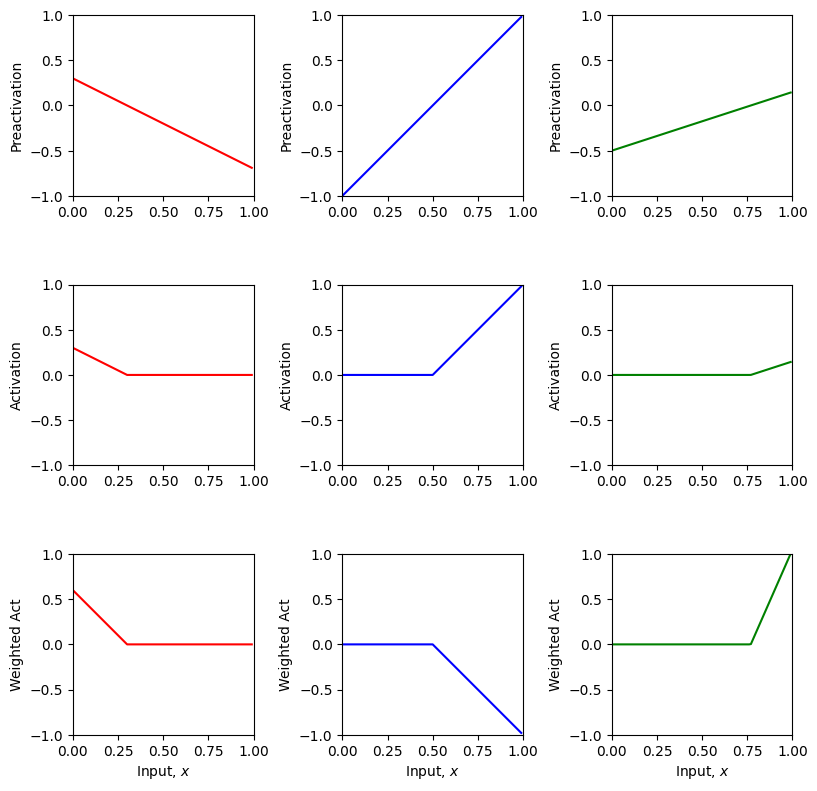

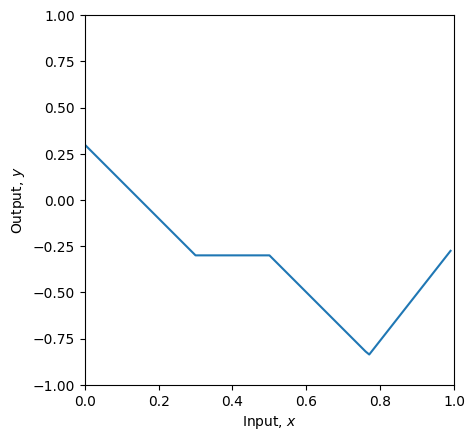

In [9]:
# Now lets define some parameters and run the neural network
theta_10 =  0.3 ; theta_11 = -1.0
theta_20 = -1.0  ; theta_21 = 2.0
theta_30 = -0.5  ; theta_31 = 0.65
phi_0 = -0.3; phi_1 = 2.0; phi_2 = -1.0; phi_3 = 7.0

# Define a range of input values
x = np.arange(0, 1, 0.01)

# We run the neural network for each of these input values
y, pre_1, pre_2, pre_3, act_1, act_2, act_3, w_act_1, w_act_2, w_act_3 = \
    shallow_net(x, ReLU, phi_0,phi_1,phi_2,phi_3, theta_10, theta_11, theta_20, theta_21, theta_30, theta_31)
# And then plot it
plot_neural_network(x, y, pre_1, pre_2, pre_3, act_1, act_2, act_3, w_act_1, w_act_2, w_act_3, plot_all=True)

In [10]:
# # Plot two shallow neural networks and the composition of the two
def plot_neural_two_components(x_in, net1_out, net2_out, net12_out=None):

  # Plot the two networks separately
  fig, ax = plt.subplots(1,2)
  fig.set_size_inches(8.5, 8.5)
  fig.tight_layout(pad=3.0)
  ax[0].plot(x_in, net1_out,'r-')
  ax[0].set_xlabel('Net 1 input'); ax[0].set_ylabel('Net 1 output')
  ax[0].set_xlim([-1,1]);ax[0].set_ylim([-1,1])
  ax[0].set_aspect(1.0)
  ax[1].plot(x_in, net2_out,'b-')
  ax[1].set_xlabel('Net 2 input'); ax[1].set_ylabel('Net 2 output')
  ax[1].set_xlim([-1,1]);ax[1].set_ylim([-1,1])
  ax[1].set_aspect(1.0)
  plt.show()

  if net12_out is not None:
    # Plot their composition
    fig, ax = plt.subplots()
    ax.plot(x_in ,net12_out,'g-')
    ax.set_xlabel('Net 1 Input'); ax.set_ylabel('Net 2 Output')
    ax.set_xlim([-1,1]);ax.set_ylim([-1,1])
    ax.set_aspect(1.0)
    plt.show()

We put the prefixes n1_ and n2_ before all the variables to make it clear which network is which.  We consider the inputs and outputs over the range [-1,1] and we plot the inputs and outputs.

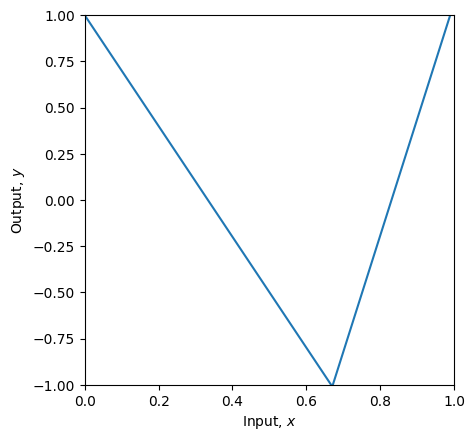

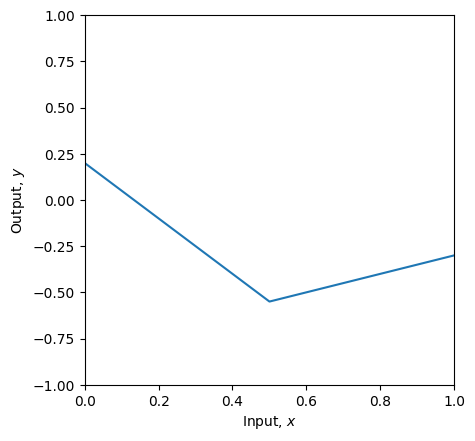

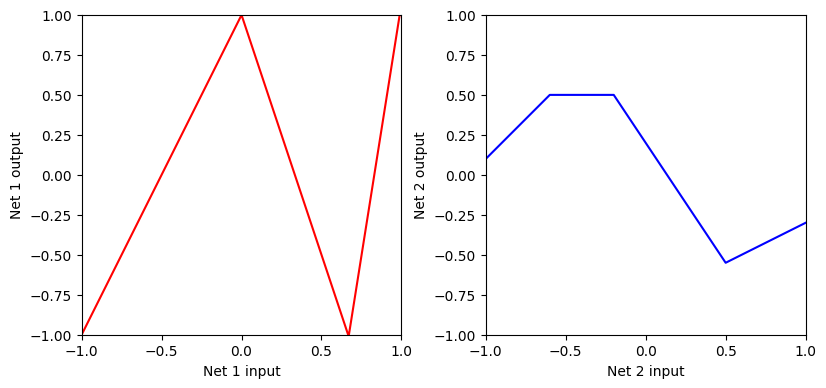

In [46]:
# Now lets define some parameters and run the first neural network
n1_theta_10 = 0.0   ; n1_theta_11 = -1.0
n1_theta_20 = 0     ; n1_theta_21 = 1.0
n1_theta_30 = -0.67 ; n1_theta_31 =  1.0
n1_phi_0 = 1.0; n1_phi_1 = -2.0; n1_phi_2 = -3.0; n1_phi_3 = 9.3

# Now lets define some parameters and run the second neural network
n2_theta_10 =  -0.6 ; n2_theta_11 = -1.0
n2_theta_20 =  0.2  ; n2_theta_21 = 1.0
n2_theta_30 =  -0.5  ; n2_theta_31 =  1.0
n2_phi_0 = 0.5; n2_phi_1 = -1.0; n2_phi_2 = -1.5; n2_phi_3 = 2.0

y1 = shallow_net(x, ReLU, n1_phi_0, n1_phi_1, n1_phi_2, n1_phi_3, n1_theta_10, n1_theta_11, n1_theta_20, n1_theta_21, n1_theta_30, n1_theta_31)[0]
y2 = shallow_net(x, ReLU, n2_phi_0, n2_phi_1, n2_phi_2, n2_phi_3, n2_theta_10, n2_theta_11, n2_theta_20, n2_theta_21, n2_theta_30, n2_theta_31)[0]

plot_neural_network(x, y1, None, None, None, None, None, None, None, None, None)
plot_neural_network(x, y2, None, None, None, None, None, None, None, None, None)
plot_neural_two_components(x, y1, y2)

x = np.arange(-1, 1, 0.001)
# We run the first and second neural networks for each of these input values and their composition network
# Plot all three graphs

Now we'll define the same neural network, but this time, we will  use matrix form.  When you get this right, it will draw the same plot as above.

In [12]:
# # Plot the shallow neural network.  Input in range [-1,1] and output [-1,1]
def plot_neural(x, y):
  fig, ax = plt.subplots()
  ax.plot(x.T,y.T)
  ax.set_xlabel('Input'); ax.set_ylabel('Output')
  ax.set_xlim([-1,1]);ax.set_ylim([-1,1])
  ax.set_aspect(1.0)
  plt.show()

In [7]:
# Make sure that input data matrix has different inputs in its columns
input = np.reshape(input, (1, -1))
def deep_net(input):
    theta_0 = np.array([n1_theta_10, n1_theta_20, n1_theta_30])
    theta_0 = np.reshape(theta_0, (-1, 1))
    theta_1 = np.array([n1_theta_11, n1_theta_21, n1_theta_31])
    theta_1 = np.reshape(theta_1, (-1, 1))

    h1 = ReLU(theta_0 + theta_1 @ input)
    h1_augmented = np.vstack([np.ones((1, input.shape[1])), h1])

    phi_0 = np.array([n2_theta_10, n2_theta_20, n2_theta_30])
    phi_0 = np.reshape(phi_0, (-1, 1))
    phi_1 = np.array([
        [n2_theta_10 + n2_theta_11 * n1_phi_0, n2_theta_11 * n1_phi_1, n2_theta_11 * n1_phi_2, n2_theta_11 * n1_phi_3],
        [n2_theta_20 + n2_theta_21 * n1_phi_0, n2_theta_21 * n1_phi_1, n2_theta_21 * n1_phi_2, n2_theta_21 * n1_phi_3],
        [n2_theta_30 + n2_theta_31 * n1_phi_0, n2_theta_31 * n1_phi_1, n2_theta_31 * n1_phi_2, n2_theta_31 * n1_phi_3],
    ])

    omega_0 = n2_phi_0
    omega_1 = np.array([n2_phi_1, n2_phi_2, n2_phi_3])

    h2 = ReLU(phi_1 @ h1_augmented)
    y = omega_0 + omega_1 @ h2
    return y

output = deep_net(input)
# Draw the network and check that it looks the same as the non-matrix version
plot_neural(input, output)

NameError: name 'n1_theta_10' is not defined

Now let's make a deep network with 3 hidden layers.  It will have $D_i=4$ inputs, $D_1=5$ neurons  in the first layer, $D_2=2$ neurons in the second layer and $D_3=4$ neurons in the third layer, and $D_o = 1$ output.

In [55]:
def deep_net(input, n_data, D_i, D_o, D_1=5, D_2=2, D_3=4):
  # We'll choose the parameters of this network randomly using np.random.normal
  beta_0 = np.random.normal(size=(D_1))
  beta_0 = np.reshape(beta_0, (-1, 1))
  
  omega_0 = np.random.normal(size=(D_1 , D_i))
  omega_0 = np.reshape(omega_0, (D_1, D_i))

  h1 = ReLU( beta_0 + omega_0 @ input )

  beta_1 = np.random.normal(size=(D_2))
  beta_1 = np.reshape(beta_1, (-1, 1))

  omega_1 = np.random.normal(size=(D_2, D_1))
  omega_1 = np.reshape(omega_1, (D_2, D_1))

  h2 = ReLU(beta_1 + omega_1 @ h1)

  beta_2 = np.random.normal(size=(D_3))
  beta_2 = np.reshape(beta_2, (-1, 1))

  omega_2 = np.random.normal(size=(D_3, D_2))
  omega_2 = np.reshape(omega_2, (D_3, D_2))

  h3 = ReLU(beta_2 + omega_2 @ h2)
  
  
  beta_4 = np.random.normal(size=(D_o))
  beta_4 = np.reshape(beta_4, (-1, 1))

  omega_3 = np.random.normal(size=(D_o, D_3))
  omega_3 = np.reshape(omega_3, (D_o, D_3))

  output = beta_4 + omega_3 @ h3

  
  # If you set the parameters to the correct sizes, the following code will run  
  if h1.shape[0] is not D_1 or h1.shape[1] is not n_data:
    print("h1 is wrong shape")
  if h2.shape[0] is not D_2 or h1.shape[1] is not n_data:
    print("h2 is wrong shape")
  if h3.shape[0] is not D_3 or h1.shape[1] is not n_data:
    print("h3 is wrong shape")
  if output.shape[0] is not D_o or h1.shape[1] is not n_data:
    print("Output is wrong shape")
  
  return output

# Print the outputs
n_data = 7
D_i = 4
D_o = 3
input = np.random.normal(size=(D_i, n_data))
output = deep_net(input, n_data, D_i, D_o)
print ("Output data points")
print(output)

Output data points
[[-0.08293218  0.03284003 -0.66412514 -0.16305988 -0.19271088 -0.66412514
  -0.12113589]
 [-1.26223389 -0.41000058  0.84980062 -1.85207742 -0.10792953  0.84980062
  -1.54346261]
 [-0.80327438 -0.53410929 -1.69138406 -0.9895676  -0.84345566 -1.69138406
  -0.89209625]]


# Binary classification

In binary classification tasks, the network predicts the probability of the output belonging to class 1.  Since probabilities must lie in [0,1] and the network can output arbitrary values, we map the network through a sigmoid function that ensures the range is valid.

In [57]:
# Sigmoid function that maps [-infty, infty] to [0, 1]
def sigmoid(model_out):
  sig_model_out = 1 / (1 + np.exp(-model_out))
  return sig_model_out

Now let's compute the likelihood

In [58]:
# Return the likelihood of all of the data under the model
def compute_likelihood(y_train, sig_model_out):
  likelihood = np.prod(sig_model_out**y_train * (1 - sig_model_out)**(1 - y_train))
  return likelihood

In [69]:
# Let's create some 1D training data
x_train = np.array([0.09291784, 0.46809093, 0.93089486, 0.67612654, 0.73441752, 0.86847339,\
                   0.49873225, 0.51083168, 0.18343972, 0.99380898, 0.27840809, 0.38028817,\
                   0.12055708, 0.56715537, 0.92005746, 0.77072270, 0.85278176, 0.05315950,\
                   0.87168699, 0.58858043])
y_train = np.array([0, 1, 1, 0, 0, 1,\
                    1, 0, 0, 1, 0, 1,\
                    0, 1, 1, 0, 1, 0,\
                    1, 1])
# Use our neural network to predict the Bernoulli parameter lambda
x_train = np.reshape(x_train, (1, -1))
model_out = deep_net(x_train, 20, D_i=1, D_o=1)
print ("model output: ", model_out)
# Compute the sigmoid
sig_model_output = sigmoid(model_out)
print ("model output after sigmoid: ", sig_model_output)
# Compute the likelihood
likelihood = compute_likelihood(y_train, sig_model_output)
# Let's double check we get the right answer before proceeding
print ("likelihood: ", likelihood)

model output:  [[-0.09485207 -0.74543311 -1.93330985 -1.27939716 -1.42901236 -1.77309295
  -0.82408005 -0.8551356  -0.19830758 -2.09479123 -0.30684488 -0.52007017
  -0.12644037 -0.99970136 -1.90549354 -1.5221967  -1.73281731 -0.04941312
  -1.78134128 -1.05469296]]
model output after sigmoid:  [[0.47630474 0.32181722 0.12638468 0.21765286 0.19325262 0.14515811
  0.30489827 0.29835666 0.45058494 0.10960412 0.42388505 0.37283583
  0.46843195 0.26900014 0.12948798 0.17913827 0.15022757 0.48764923
  0.14413759 0.25832494]]
likelihood:  2.3521107339152144e-10


You can see that this gives a very small answer, even for this small 1D dataset, and with the model fitting quite well.  This is because it is the product of several probabilities, which are all quite small themselves.
This will get out of hand pretty quickly with real datasets -- the likelihood will get so small that we can't represent it with normal finite-precision math

This is why we use negative log likelihood

In [70]:
# Return the negative log likelihood of the data under the model
def compute_negative_log_likelihood(y_train, sig_model_out):
  likelihood = compute_likelihood(y_train, sig_model_out)
  nll = -np.log(likelihood)
  return nll

In [80]:
# Let's create some 1D training data
x_train = np.array([0.09291784, 0.46809093, 0.93089486, 0.67612654, 0.73441752, 0.86847339,\
                   0.49873225, 0.51083168, 0.18343972, 0.99380898, 0.27840809, 0.38028817,\
                   0.12055708, 0.56715537, 0.92005746, 0.77072270, 0.85278176, 0.05315950,\
                   0.87168699, 0.58858043])
y_train = np.array([0, 1, 1, 0, 0, 1,\
                    1, 0, 0, 1, 0, 1,\
                    0, 1, 1, 0, 1, 0,\
                    1, 1])
# Use our neural network to predict the Bernoulli parameter lambda
x_train = np.reshape(x_train, (1, -1))
model_out = deep_net(x_train, 20, D_i=1, D_o=1)
print ("model output: ", model_out)
# Compute the sigmoid
sig_model_output = sigmoid(model_out)
print ("model output after sigmoid: ", sig_model_output)
# Compute the likelihood
likelihood = compute_likelihood(y_train, sig_model_output)
print ("likelihood: ", likelihood)
nll = compute_negative_log_likelihood(y_train, sig_model_output)
print ("nll: ", nll)

model output:  [[-1.59946009 -1.59946009 -1.59946009 -1.59946009 -1.59946009 -1.59946009
  -1.59946009 -1.59946009 -1.59946009 -1.59946009 -1.59946009 -1.59946009
  -1.59946009 -1.59946009 -1.59946009 -1.59946009 -1.59946009 -1.59946009
  -1.59946009 -1.59946009]]
model output after sigmoid:  [[0.16805709 0.16805709 0.16805709 0.16805709 0.16805709 0.16805709
  0.16805709 0.16805709 0.16805709 0.16805709 0.16805709 0.16805709
  0.16805709 0.16805709 0.16805709 0.16805709 0.16805709 0.16805709
  0.16805709 0.16805709]]
likelihood:  5.765897323550552e-10
nll:  21.27389013810608


# Multiclass classification

For multiclass classification, the network must predict the probability of $K$ classes, using $K$ outputs.  However, these probability must be non-negative and sum to one, and the network outputs can take arbitrary values.  Hence, we pass the outputs through a softmax function which maps $K$ arbitrary values to $K$ non-negative values that sum to one.

In [82]:
# Softmax function that maps a vector of arbitrary values to a vector of values that are positive and sum to one.
def softmax(model_out):
    softmax_model_out = np.exp(model_out) / np.sum(np.exp(model_out), axis=0)
    return softmax_model_out

In [88]:
# Return the likelihood of all of the data under the model
def compute_likelihood(y_train, softmax_model_out):
    likelihood = np.prod(softmax_model_out[y_train, np.arange(y_train.shape[0])])
    return likelihood

In [89]:
# Let's create some 1D training data
x_train = np.array([0.09291784, 0.46809093, 0.93089486, 0.67612654, 0.73441752, 0.86847339,\
                   0.49873225, 0.51083168, 0.18343972, 0.99380898, 0.27840809, 0.38028817,\
                   0.12055708, 0.56715537, 0.92005746, 0.77072270, 0.85278176, 0.05315950,\
                   0.87168699, 0.58858043])
y_train = np.array([2, 0, 1, 2, 1, 0,\
                    0, 2, 2, 0, 2, 0,\
                    2, 0, 1, 2, 1, 2, \
                    1, 0])
# Use our neural network to predict the Bernoulli parameter lambda
x_train = np.reshape(x_train, (1, -1))
model_out = deep_net(x_train, 20, D_i=1, D_o=3)
print ("model output: ", model_out)
# Compute the softmax
softmax_model_output = softmax(model_out)
print ("model output after softmax: ", softmax_model_output)
# Compute the likelihood
likelihood = compute_likelihood(y_train, softmax_model_output)
# Let's double check we get the right answer before proceeding
print ("likelihood: ", likelihood)

model output:  [[ 0.51655569  0.51655569  0.51655569  0.51655569  0.51655569  0.51655569
   0.51655569  0.51655569  0.51655569  0.51655569  0.51655569  0.51655569
   0.51655569  0.51655569  0.51655569  0.51655569  0.51655569  0.51655569
   0.51655569  0.51655569]
 [ 1.54248367  1.54248367  1.54248367  1.54248367  1.54248367  1.54248367
   1.54248367  1.54248367  1.54248367  1.54248367  1.54248367  1.54248367
   1.54248367  1.54248367  1.54248367  1.54248367  1.54248367  1.54248367
   1.54248367  1.54248367]
 [-0.71416801 -0.71416801 -0.71416801 -0.71416801 -0.71416801 -0.71416801
  -0.71416801 -0.71416801 -0.71416801 -0.71416801 -0.71416801 -0.71416801
  -0.71416801 -0.71416801 -0.71416801 -0.71416801 -0.71416801 -0.71416801
  -0.71416801 -0.71416801]]
model output after softmax:  [[0.24499211 0.24499211 0.24499211 0.24499211 0.24499211 0.24499211
  0.24499211 0.24499211 0.24499211 0.24499211 0.24499211 0.24499211
  0.24499211 0.24499211 0.24499211 0.24499211 0.24499211 0.24499211
  0.

In [ ]:
# Return the negative log likelihood of the data under the model
def compute_negative_log_likelihood(y_train, softmax_model_out):
  
  return nll

In [ ]:
# Let's create some 1D training data
x_train = np.array([0.09291784, 0.46809093, 0.93089486, 0.67612654, 0.73441752, 0.86847339,\
                   0.49873225, 0.51083168, 0.18343972, 0.99380898, 0.27840809, 0.38028817,\
                   0.12055708, 0.56715537, 0.92005746, 0.77072270, 0.85278176, 0.05315950,\
                   0.87168699, 0.58858043])
y_train = np.array([2, 0, 1, 2, 1, 0,\
                    0, 2, 2, 0, 2, 0,\
                    2, 0, 1, 2, 1, 2, \
                    1, 0])
# Use our neural network to predict the Bernoulli parameter lambda
x_train = np.reshape(x_train, (1, -1))
model_out = deep_net(x_train, 20, D_i=1, D_o=3)
print ("model output: ", model_out)
# Compute the softmax
softmax_model_output = softmax(model_out)
print ("model output after softmax: ", softmax_model_output)
# Compute the likelihood
likelihood = compute_likelihood(y_train, softmax_model_output)
# Let's double check we get the right answer before proceeding
print ("likelihood: ", likelihood)
nll = compute_negative_log_likelihood(y_train, softmax_model_output)
print ("nll: ", nll)